# Chapitre 8 - Cours 3 : Traitement des données

Après la curation (cours 1) et la synthèse (cours 2), on dispose d'un jeu **brut** :
des données publiques, internes, synthétiques, assemblées de bric et de broc. Ce
notebook suit la section *Data Processing* du livre et transforme ce jeu brut en jeu
prêt pour l'affinage :

1. **inspecter** les données (section *Inspect Data*) : distributions, langues, scores
   par annotateur, conflits ;
2. **dédupliquer exactement** par hachage (section *Deduplicate Data*) ;
3. détecter les **quasi-doublons** avec **MinHash et LSH**, implémentés et visualisés ;
4. **nettoyer et filtrer** (section *Clean and Filter Data*) : HTML, données
   personnelles, heuristiques de qualité ;
5. **mettre au format** (section *Format Data*) : chat template, masquage de la perte,
   pièges de format ;
6. assembler le tout en un **pipeline** et réfléchir à l'ordre des étapes.

Le fil rouge est un petit jeu d'instructions volontairement « sale », construit par
`messy_instruction_dataset()` : une trentaine de paires propres auxquelles on a injecté
doublons, quasi-doublons, balises HTML, données personnelles, réponses vides ou qui
répètent l'instruction, et un annotateur trop généreux. La colonne `kind` (le défaut
injecté) est inconnue en pratique ; elle nous sert seulement à **évaluer** nos filtres.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

from aie import ch08_donnees as d8
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.max_colwidth", 80)
tok = AutoTokenizer.from_pretrained(llm.SMALL)
ntok = lambda t: len(tok(t, add_special_tokens=False)["input_ids"])


def titre(ax, texte, sous_titre):
    ax.set_title(texte, pad=18)
    subtitle(ax, sous_titre)

def log_lisible(ax, axes="y"):
    """Graduations log au format décimal simple (la police du socle n'a pas le signe moins
    typographique utilisé par les exposants mathtext)."""
    from matplotlib.ticker import FuncFormatter, NullFormatter
    for a in axes:
        axis = ax.yaxis if a == "y" else ax.xaxis
        axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        axis.set_minor_formatter(NullFormatter())


brut = d8.messy_instruction_dataset(seed=0)
print(f"{len(brut)} exemples bruts")
brut.drop(columns="kind").head(8)

69 exemples bruts


,id,source,annotator,instruction,response,score
0,0,interne,A2,How do I make a basic vinaigrette?,How do I make a basic vinaigrette?,4
1,1,interne,A2,Explique la différence entre une liste et un tuple en Python.,Une liste est modifiable (mutable) alors qu'un tuple ne l'est pas ; un tuple...,4
2,2,interne,A2,"Write a reminder for John Smith (john.smith@mail.com, +1 415 555 0134).","Hi John, this is a reminder about tomorrow's meeting. Reach us at +1 415 555...",4
3,3,interne,A3,Salut ?,Bonjour ! Comment puis-je vous aider ?,5
4,4,forum,A3,Qu'est-ce qu'un taux d'intérêt composé ? <br>,"<div class=""post""><p>Les intérêts sont ajoutés au capital à chaque période e...",5
5,5,forum,A3,what should I pack a weekend hiking trip?,"Layers of clothing, rain jacket, sturdy shoes, water, snacks, a map, a headl...",5
6,6,public_hf,A3,Combien d'heures de sommeil recommande-t-on pour un adulte ?,"Entre sept et neuf heures par nuit pour la plupart des adultes, selon les re...",5
7,7,public_hf,A3,Comment expliquer les fractions à un enfant de huit ans ?,Comment expliquer les fractions à un enfant de huit ans ?,5


Avant de commencer, trois conseils pratiques du livre pour les gros volumes, où chaque
étape peut prendre des heures :

- **ordonner** les étapes pour économiser du calcul (dédupliquer d'abord si le nettoyage
  est coûteux, et inversement ; voir la section 6) ;
- faire des **essais à blanc** sur un échantillon avant de lancer un script sur tout ;
- ne **jamais modifier les données en place** : garder l'original, car une autre équipe
  peut en avoir besoin autrement, et un bug peut corrompre les données. Ici, `brut` ne
  sera jamais modifié : chaque étape produit une nouvelle table.

## 1. Inspecter les données (section *Inspect Data*)

**Première chose à faire** : regarder. D'où viennent les données ? Comment ont-elles été
traitées ? Quelles distributions de longueurs, de langues, de sujets ? Le livre cite
Greg Brockman : l'inspection manuelle des données a probablement le meilleur rapport
valeur sur prestige de toutes les activités de l'apprentissage automatique. Quinze
minutes à fixer les données évitent souvent des heures de débogage.

### Longueurs, sources et langues

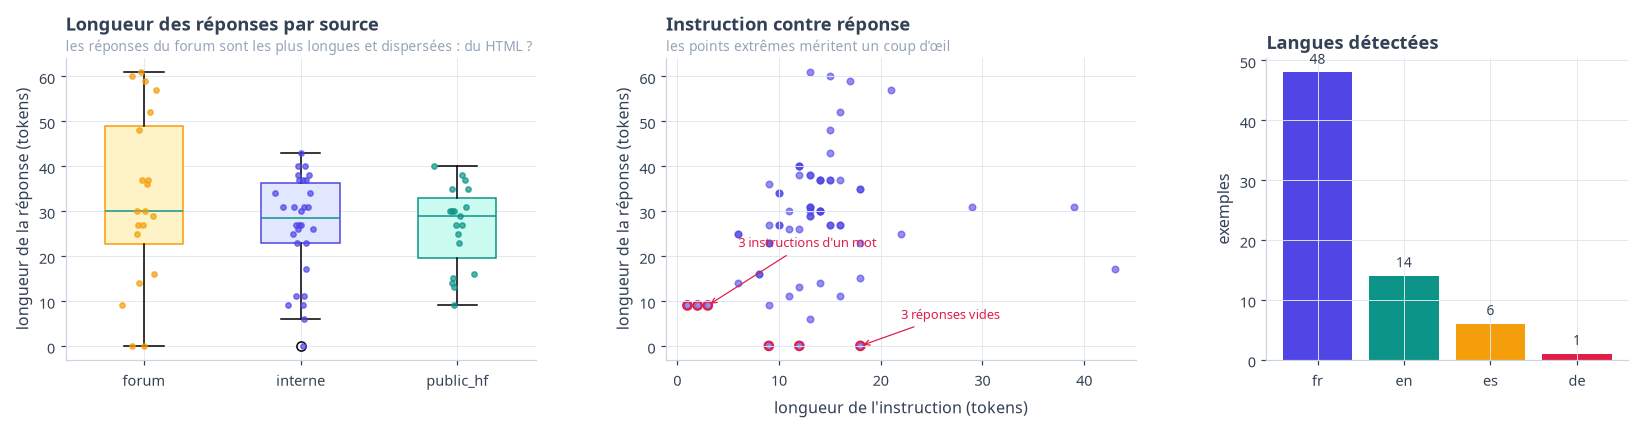

In [2]:
insp = brut.copy()
insp["tokens instr."] = insp.instruction.map(ntok)
insp["tokens rép."] = insp.response.map(ntok)
insp["langue"] = (insp.instruction + " " + insp.response).map(d8.detect_language)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1.3, 1.3, 1]})
ax = axes[0]
sources = ["forum", "interne", "public_hf"]
data = [insp.loc[insp.source == s, "tokens rép."] for s in sources]
bp = ax.boxplot(data, tick_labels=sources, patch_artist=True, widths=0.5)
for patch, c in zip(bp["boxes"], [AMBER, INDIGO, TEAL]):
    patch.set_facecolor(LIGHT[c]); patch.set_edgecolor(c)
for i, dd in enumerate(data):
    ax.scatter(np.full(len(dd), i + 1) + np.random.default_rng(i).normal(0, 0.06, len(dd)), dd, s=12,
               color=[AMBER, INDIGO, TEAL][i], zorder=3, alpha=0.7)
ax.set_ylabel("longueur de la réponse (tokens)")
titre(ax, "Longueur des réponses par source", "les réponses du forum sont les plus longues et dispersées : du HTML ?")
ax = axes[1]
ax.scatter(insp["tokens instr."], insp["tokens rép."], s=18, color=INDIGO, alpha=0.6)
vides = insp[insp["tokens rép."] == 0]
courts = insp[insp["tokens instr."] < 4]
ax.scatter(vides["tokens instr."], vides["tokens rép."], s=30, facecolor="none", edgecolor=ROSE, lw=1.5)
ax.scatter(courts["tokens instr."], courts["tokens rép."], s=30, facecolor="none", edgecolor=ROSE, lw=1.5)
ax.annotate(f"{len(vides)} réponses vides", (vides["tokens instr."].max(), 0), xytext=(22, 6), fontsize=8.5,
            color=ROSE, arrowprops=dict(arrowstyle="->", color=ROSE, lw=0.8))
ax.annotate(f"{len(courts)} instructions d'un mot", (courts["tokens instr."].max(), courts["tokens rép."].max()),
            xytext=(6, 22), fontsize=8.5, color=ROSE, arrowprops=dict(arrowstyle="->", color=ROSE, lw=0.8))
ax.set_xlabel("longueur de l'instruction (tokens)")
ax.set_ylabel("longueur de la réponse (tokens)")
titre(ax, "Instruction contre réponse", "les points extrêmes méritent un coup d'œil")
ax = axes[2]
lc = insp.langue.value_counts()
ax.bar(lc.index, lc.values, color=[INDIGO, TEAL, AMBER, ROSE][:len(lc)])
annotate_bars(ax, "{:.0f}")
ax.set_ylabel("exemples")
ax.set_title("Langues détectées")
finish(fig)
plt.show()

Ces trois graphiques soulèvent déjà des questions. Les réponses du forum sont longues,
mais en partie à cause de balises HTML (nous le vérifierons). Quelques points sont
aberrants : réponses vides, instructions d'un mot (« Aide », « ok »). Le jeu mélange
quatre langues : si l'application est francophone, les exemples en espagnol ou en
allemand sont-ils **pertinents** (cours 1, critère de qualité) ? Notre détecteur de
langue est rudimentaire (comptage de mots-outils) mais suffit pour une inspection ; en
production, on utiliserait un classifieur dédié.

### Le type d'instruction

Le livre cite une analyse de Microsoft qui compare GPT-3 et GPT-4 par la distribution des
couples (verbe, nom) de leurs instructions et par la longueur de leurs réponses. Une
version simple : le **premier mot** des instructions, qui révèle leur forme (question en
« comment », consigne à l'impératif...).

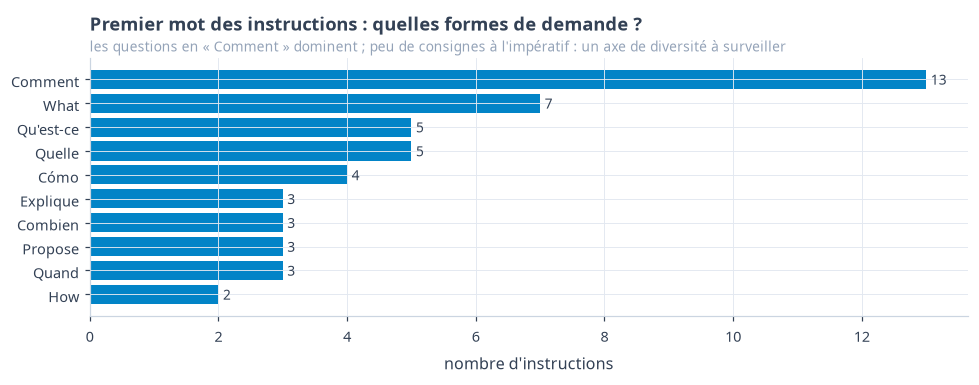

In [3]:
premier = insp.instruction.str.split().str[0].str.strip("¿?,.").str.capitalize()
pc = premier.value_counts().head(10)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(pc.index[::-1], pc.values[::-1], color=SKY)
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("nombre d'instructions")
titre(ax, "Premier mot des instructions : quelles formes de demande ?",
      "les questions en « Comment » dominent ; peu de consignes à l'impératif : un axe de diversité à surveiller")
finish(fig)
plt.show()

### Les annotateurs

Le livre conseille de tracer les distributions **par annotateur** : certains donnent des
réponses plus courtes, d'autres des scores plus élevés. Nos exemples portent un score de
qualité de 1 à 5 attribué par l'un des trois annotateurs.

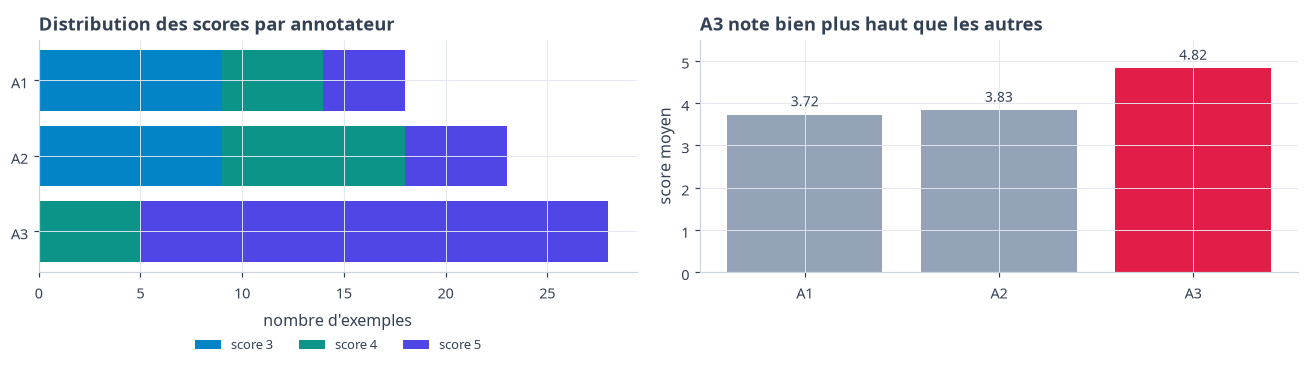

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
ct = pd.crosstab(insp.annotator, insp.score)
bottom = np.zeros(len(ct))
for sc, c in zip(ct.columns, [ROSE, AMBER, SKY, TEAL, INDIGO][-len(ct.columns):]):
    ax.barh(ct.index, ct[sc], left=bottom, color=c, label=f"score {sc}")
    bottom += ct[sc].values
ax.invert_yaxis()
ax.set_xlabel("nombre d'exemples")
ax.set_title("Distribution des scores par annotateur")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=8.5)
ax = axes[1]
m = insp.groupby("annotator").score.mean()
ax.bar(m.index, m.values, color=[GRAY, GRAY, ROSE])
annotate_bars(ax, "{:.2f}")
ax.set_ylim(0, 5.5)
ax.set_ylabel("score moyen")
ax.set_title("A3 note bien plus haut que les autres")
finish(fig)
plt.show()

L'annotateur A3 met 5 presque partout. Est-il tombé sur de meilleurs exemples, ou est-il
trop généreux ? Comme les exemples sont répartis au hasard entre annotateurs, la
seconde hypothèse est la plus probable. Options : recalibrer ses scores (par exemple les
centrer-réduire par annotateur), faire réannoter un échantillon, ou ignorer ses scores.

### Même instruction, réponses différentes

Autre question du livre : y a-t-il des exemples avec la **même instruction mais des
réponses différentes** (ou l'inverse) ? Ce sont des conflits à résoudre.

In [5]:
insp["instr_norm"] = insp.instruction.map(d8.normalize_text)
grp = insp[insp.response.str.strip() != ""].groupby("instr_norm").response.nunique()
conflits = grp[grp > 1].index
vue = insp[insp.instr_norm.isin(conflits)].sort_values("instr_norm")
vue["réponse"] = vue.response.map(lambda t: d8.strip_html(t)[:70])
vue[["id", "annotator", "score", "instruction", "réponse"]].head(10)

,id,annotator,score,instruction,réponse
6,6,A3,5,Combien d'heures de sommeil recommande-t-on pour un adulte ?,"Entre sept et neuf heures par nuit pour la plupart des adultes, selon"
8,8,A3,4,Combien d'heures de sommeil recommande-t-on pour un adulte ?,Quatre heures suffisent largement pour un adulte en bonne santé.
51,51,A1,5,Combien d'heures de sommeil recommande-t-on pour un adulte ?,
7,7,A3,5,Comment expliquer les fractions à un enfant de huit ans ?,Comment expliquer les fractions à un enfant de huit ans ?
32,32,A3,5,Comment expliquer les fractions à un enfant de huit ans ?,Partez d'une pizza : si on la coupe en quatre parts égales et qu'on en
47,47,A3,5,Comment expliquer les fractions à un enfant de huit ans ?,Partez d'une pizza : si on la coupe en quatre parts égales et qu'on en
0,0,A2,4,How do I make a basic vinaigrette?,How do I make a basic vinaigrette?
44,44,A1,3,How do I make a basic vinaigrette?,"Whisk three parts oil with one part vinegar, add a pinch of salt, pepp"
26,26,A3,5,Quelle est la durée légale du travail en France ?,La durée légale est de 39 heures par semaine.
41,41,A3,5,Quelle est la durée légale du travail en France ?,"La durée légale est de 35 heures par semaine ; au-delà, les heures son"


Parmi ces groupes, certains ne sont que des variantes de format (HTML) d'une même
réponse, mais d'autres sont de vrais **conflits** : « quatre heures de sommeil
suffisent », « 39 heures par semaine »... Ces réponses fausses, notées 5 par A3, sont
exactement ce que le livre recommande de traquer : la vérification des faits et le
croisement des annotations. Un humain doit trancher.

> **À retenir.** Inspecter d'abord : distributions de longueurs (par source), langues,
> formes d'instructions, scores par annotateur, conflits entre exemples. Les outils
> aident, mais rien ne remplace quinze minutes de lecture attentive des données.

## 2. Déduplication exacte (section *Deduplicate Data*)

**Pourquoi dédupliquer ?** Les doublons faussent la distribution et introduisent des
biais. Le livre l'illustre par un jeu jouet de produits où un même exemple dupliqué
fait croire que « rouge » rime avec « cher ». Reproduisons l'idée.

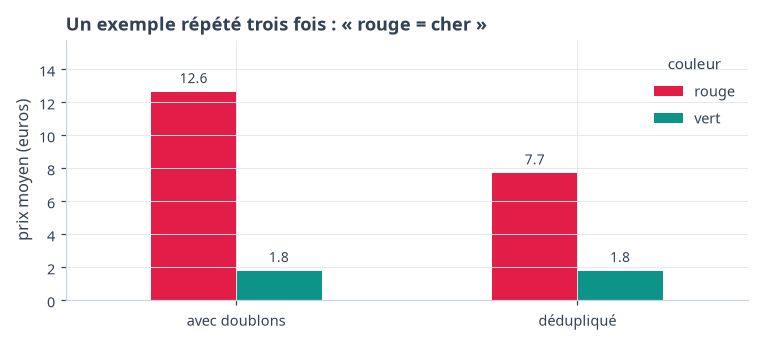

In [6]:
jouet = pd.DataFrame({"article": ["crayon", "compas", "crayon", "crayon", "crayon", "gomme", "gomme", "règle", "stylo"],
                      "couleur": ["rouge", "vert", "rouge", "rouge", "vert", "rouge", "vert", "rouge", "vert"],
                      "prix (euros)": [20, 2, 20, 20, 1, 1, 1, 2, 3]})
ded = jouet.drop_duplicates()
comp = pd.DataFrame({"avec doublons": jouet.groupby("couleur")["prix (euros)"].mean(),
                     "dédupliqué": ded.groupby("couleur")["prix (euros)"].mean()})
fig, ax = plt.subplots(figsize=(7, 3.2))
comp.T.plot.bar(ax=ax, color=[ROSE, TEAL], rot=0)
annotate_bars(ax, "{:.1f}")
ax.set_ylabel("prix moyen (euros)")
ax.set_ylim(0, comp.values.max() * 1.25)
ax.set_title("Un exemple répété trois fois : « rouge = cher »")
ax.legend(title="couleur", loc="upper right")
finish(fig)
plt.show()

Le livre ajoute d'autres méfaits : la **contamination** du test (un doublon côté
entraînement, l'autre côté test, et l'évaluation est faussée), et la dégradation des
performances : une étude d'Anthropic montre que répéter 0,1 % des données 100 fois peut
ramener un modèle de 800 millions de paramètres au niveau d'un modèle deux fois plus
petit. Au minimum, les doublons gaspillent du calcul.

Les doublons ont plusieurs formes (document entier, paragraphe répété dans un document,
citation répétée entre documents) et plusieurs niveaux (document, phrase, token). Le plus
simple est le **hachage exact** : on calcule une empreinte (SHA-1) de chaque exemple et
l'on garde un représentant par empreinte. Coût : $O(n)$. Mais « exact » dépend de la
**normalisation** préalable (casse, espaces, ponctuation).

In [7]:
cle_brute = (brut.instruction + "\x00" + brut.response).map(lambda t: d8.exact_hash(t, normalize=False))
cle_norm = (brut.instruction.map(d8.normalize_text) + "\x00" + brut.response.map(d8.normalize_text)).map(d8.exact_hash)
dup_norm = cle_norm.duplicated()
res = pd.DataFrame({
    "hachage": ["brut", "après normalisation"],
    "exemples uniques": [cle_brute.nunique(), cle_norm.nunique()],
    "doublons retirés": [len(brut) - cle_brute.nunique(), len(brut) - cle_norm.nunique()],
    # un quasi-doublon injecté est « attrapé » s'il partage son empreinte avec un autre exemple
    "quasi-doublons injectés attrapés (sur 10)": [
        brut.kind[cle_brute.duplicated(keep=False)].eq("quasi_doublon").sum(),
        brut.kind[cle_norm.duplicated(keep=False)].eq("quasi_doublon").sum()],
})
res

,hachage,exemples uniques,doublons retirés,quasi-doublons injectés attrapés (sur 10)
0,brut,60,9,1
1,après normalisation,55,14,6


Le hachage brut ne retire que les copies au caractère près. La normalisation (minuscules,
espaces compactés, ponctuation finale ôtée) en attrape davantage : les quasi-doublons qui
ne diffèrent que par la casse ou un espace. Les quasi-doublons qui changent un **mot**
lui échappent : il faut une mesure de similarité (section 3).

**Contamination.** Découpons le jeu brut en entraînement (80 %) et test (20 %) au hasard,
et mesurons la part du test qui a un doublon (normalisé) côté entraînement, avant et
après déduplication.

In [8]:
def contamination(df, seed):
    r = np.random.default_rng(seed)
    idx = r.permutation(len(df))
    cut = int(0.8 * len(df))
    k = (df.instruction.map(d8.normalize_text) + "|" + df.response.map(d8.normalize_text)).values
    train, test = set(k[idx[:cut]]), k[idx[cut:]]
    return np.mean([t in train for t in test])


avant = np.mean([contamination(brut, s) for s in range(200)])
dedup1 = brut[~dup_norm].reset_index(drop=True)
apres = np.mean([contamination(dedup1, s) for s in range(200)])
print(f"Part du test présente à l'identique dans l'entraînement : {avant:.1%} avant, {apres:.1%} après déduplication")

Part du test présente à l'identique dans l'entraînement : 31.9% avant, 0.0% après déduplication


Avec nos doublons volontairement nombreux, une part considérable du test serait « déjà
vue » sans déduplication : le score de test serait gonflé d'autant (et la contamination
par quasi-doublons, non mesurée ici, s'y ajouterait). Règle : **dédupliquer avant de découper**.

> **À retenir.** Les doublons biaisent la distribution, contaminent le test et gaspillent
> du calcul. Le hachage exact, en $O(n)$, est la première passe ; sa puissance dépend de
> la normalisation. On déduplique **avant** de séparer entraînement et test.

## 3. Quasi-doublons : MinHash et LSH (section *Deduplicate Data*)

Le livre liste trois familles de méthodes : la **comparaison par paires** (exacte mais
en $O(n^2)$), le **hachage** dans des seaux (MinHash, filtres de Bloom) et la **réduction
de dimension** (les index vectoriels du chapitre 6). Nous implémentons la plus classique
pour le texte : **MinHash + LSH**.

### Étape 1 : des ensembles et la similarité de Jaccard

On représente chaque texte par l'ensemble de ses **shingles** : ses sous-chaînes de $k$
caractères (ou $k$ mots) consécutifs. La similarité de deux textes est alors la
**similarité de Jaccard** de leurs ensembles :
$$J(A, B) = \frac{|A \cap B|}{|A \cup B|} \in [0, 1].$$

In [9]:
a = "Comment annuler le dernier commit Git sans perdre les modifications ?"
b = "comment annuler le dernier commit Git sans  perdre les modifications"
c = "Comment annuler un commit Git déjà poussé sur le serveur ?"
Sa, Sb, Sc = (d8.shingles(t, 5) for t in (a, b, c))
print("Quelques 5-shingles de a :", sorted(Sa)[:6])
print(f"|A| = {len(Sa)}, J(a, b) = {d8.jaccard(Sa, Sb):.2f}, J(a, c) = {d8.jaccard(Sa, Sc):.2f}")

Quelques 5-shingles de a : [' annu', ' comm', ' dern', ' git ', ' le d', ' les ']
|A| = 63, J(a, b) = 1.00, J(a, c) = 0.22


### Étape 2 : MinHash, une signature courte qui estime Jaccard

Comparer des ensembles de centaines de shingles coûte cher. **MinHash** les résume par
une **signature** de $k$ entiers. On tire $k$ fonctions de hachage aléatoires
$h_i(x) = (a_i x + b_i) \bmod p$ (qui se comportent comme des permutations aléatoires
des shingles) et l'on garde pour chacune la **plus petite valeur** sur l'ensemble :
$\mathrm{sig}_i(A) = \min_{x \in A} h_i(x)$.

**Propriété clé (petite démonstration).** Pour une permutation aléatoire, le plus petit
élément de $A \cup B$ est équiprobablement n'importe lequel de ses éléments. Les deux
minimums coïncident exactement quand ce plus petit élément est dans $A \cap B$. Donc
$$\Pr\big[\mathrm{sig}_i(A) = \mathrm{sig}_i(B)\big] = \frac{|A \cap B|}{|A \cup B|} = J(A, B).$$
La proportion de composantes égales $\hat J$ est un estimateur **sans biais** de $J$,
moyenne de $k$ variables de Bernoulli : son écart-type vaut $\sqrt{J(1-J)/k}$.

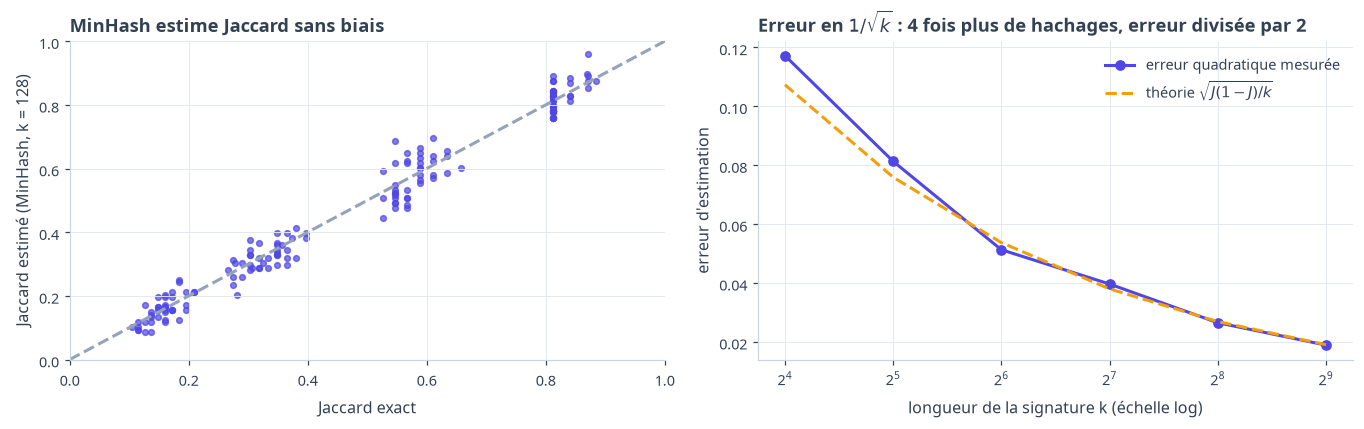

In [10]:
Sd, paires = [], []
for e_rate, sd in [(0.03, 1), (0.1, 2), (0.2, 3), (0.35, 4)]:   # plusieurs niveaux d'édition
    dd, vp = d8.make_near_duplicate_corpus(80, dup_frac=0.5, edit_rate=e_rate, seed=sd)
    off = len(Sd)
    Sd += [d8.shingles(x, 3, "word") for x in dd]
    paires += [(i + off, j + off) for i, j in sorted(vp)]
Jvrai = np.array([d8.jaccard(Sd[i], Sd[j]) for i, j in paires])
ks = [16, 32, 64, 128, 256, 512]
err = []
for k in ks:
    mh = d8.MinHasher(k, seed=3)
    sig = {i: mh.signature(Sd[i]) for p in paires for i in p}
    est = np.array([d8.minhash_jaccard(sig[i], sig[j]) for i, j in paires])
    err.append(np.sqrt(np.mean((est - Jvrai) ** 2)))
Jm = Jvrai.mean()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
ax = axes[0]
mh = d8.MinHasher(128, seed=3)
est128 = np.array([d8.minhash_jaccard(mh.signature(Sd[i]), mh.signature(Sd[j])) for i, j in paires])
ax.scatter(Jvrai, est128, s=14, color=INDIGO, alpha=0.7)
ax.plot([0, 1], [0, 1], color=GRAY, ls="--")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Jaccard exact")
ax.set_ylabel("Jaccard estimé (MinHash, k = 128)")
ax.set_title("MinHash estime Jaccard sans biais")
ax = axes[1]
ax.plot(ks, err, "o-", color=INDIGO, label="erreur quadratique mesurée")
ax.plot(ks, np.sqrt(np.mean(Jvrai * (1 - Jvrai)) / np.array(ks)), "--", color=AMBER, label="théorie $\\sqrt{J(1-J)/k}$")
ax.set_xscale("log", base=2)
ax.set_xlabel("longueur de la signature k (échelle log)")
ax.set_ylabel("erreur d'estimation")
ax.set_title("Erreur en $1/\\sqrt{k}$ : 4 fois plus de hachages, erreur divisée par 2")
ax.legend()
finish(fig)
plt.show()

### Étape 3 : LSH, ne comparer que les candidats

Même avec des signatures, comparer toutes les paires reste en $O(n^2)$. Le **hachage
sensible à la localité** (LSH) découpe chaque signature en $b$ **bandes** de $r$
composantes ($b \times r = k$) et range chaque bande dans une table de hachage. Deux
documents deviennent **candidats** s'ils tombent dans le même seau pour au moins une
bande. Pour une paire de similarité $s$ :

- une bande coïncide avec probabilité $s^r$ (les $r$ composantes doivent coïncider) ;
- aucune bande ne coïncide avec probabilité $(1 - s^r)^b$ ;
- donc $\Pr[\text{candidate}] = 1 - (1 - s^r)^b$.

Cette fonction a une forme en **S** dont le point d'inflexion est proche de
$s^\star \approx (1/b)^{1/r}$ : on règle $(b, r)$ pour placer le seuil où l'on veut.

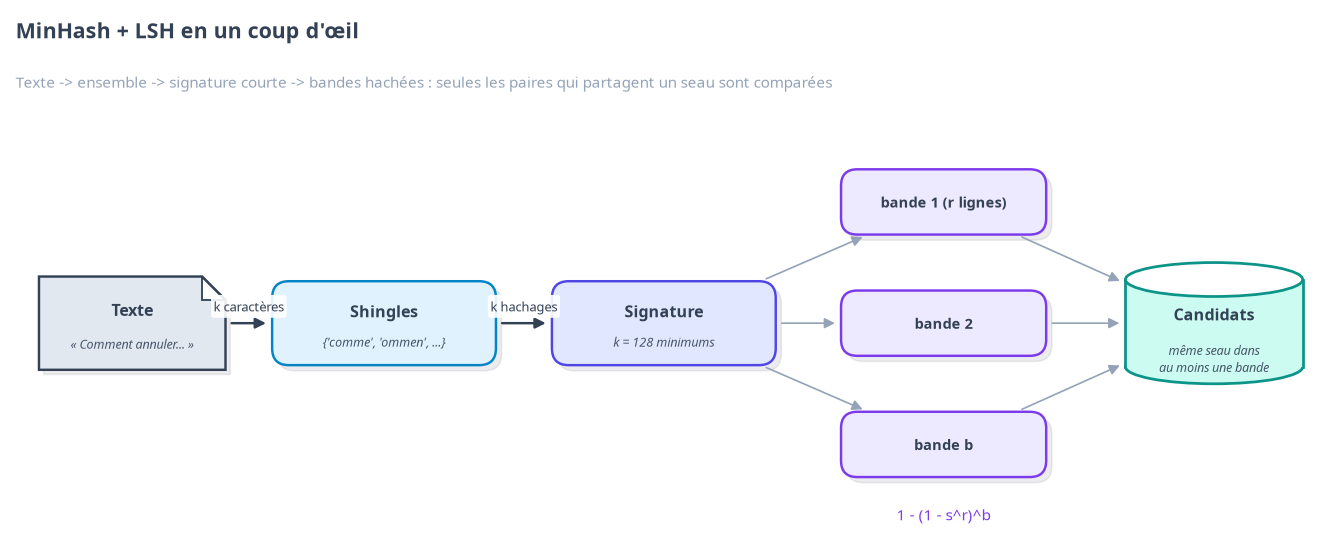

In [11]:
d = Diagram(14, 4.8, title="MinHash + LSH en un coup d'œil",
            subtitle="Texte -> ensemble -> signature courte -> bandes hachées : seules les paires qui partagent un seau sont comparées")
d.box("t", 1.3, 2.4, "Texte", sub="« Comment annuler... »", color=SLATE, kind="doc", w=2.0, h=1.0)
d.box("sh", 4.0, 2.4, "Shingles", sub="{'comme', 'ommen', ...}", color=SKY, w=2.4)
d.box("sig", 7.0, 2.4, "Signature", sub="k = 128 minimums", color=INDIGO, w=2.4)
d.arrow("t", "sh", "k caractères")
d.arrow("sh", "sig", "k hachages")
for i, (lab, y) in enumerate([("bande 1 (r lignes)", 3.7), ("bande 2", 2.4), ("bande b", 1.1)]):
    d.box(f"b{i}", 10.0, y, lab, color=VIOLET, w=2.2, h=0.7, fontsize=9.5)
    d.arrow("sig", f"b{i}", color=GRAY, lw=1.1)
d.box("cand", 12.9, 2.4, "Candidats", sub="même seau dans\nau moins une bande", color=TEAL, kind="db", w=1.9, h=1.3)
for i in range(3):
    d.arrow(f"b{i}", "cand", color=GRAY, lw=1.1)
d.note(10.0, 0.35, "1 - (1 - s^r)^b", color=VIOLET, fontsize=10, style="normal")
d.show()

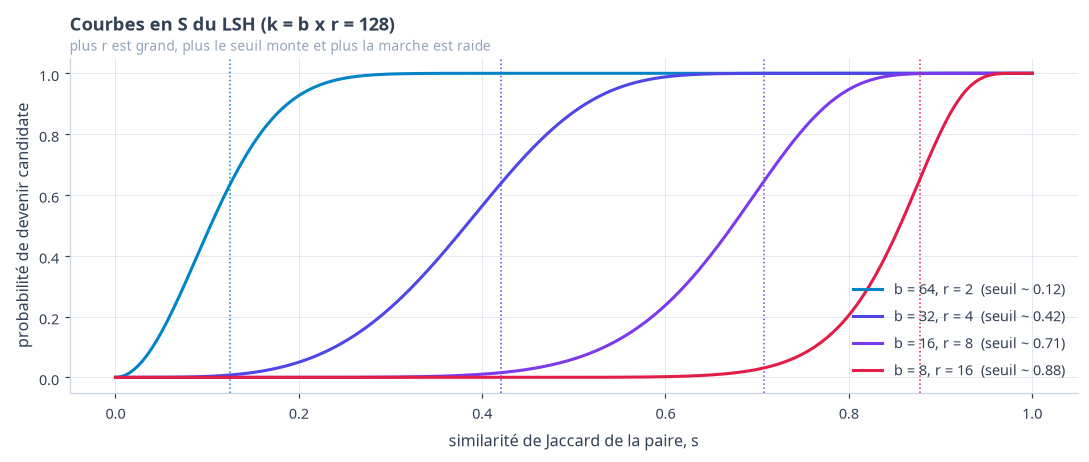

In [12]:
s = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(10, 4.3))
for (bb, rr), c in zip([(64, 2), (32, 4), (16, 8), (8, 16)], [SKY, INDIGO, VIOLET, ROSE]):
    ax.plot(s, d8.lsh_probability(s, bb, rr), color=c, label=f"b = {bb}, r = {rr}  (seuil ~ {d8.lsh_threshold(bb, rr):.2f})")
    ax.axvline(d8.lsh_threshold(bb, rr), color=c, ls=":", lw=1)
ax.set_xlabel("similarité de Jaccard de la paire, s")
ax.set_ylabel("probabilité de devenir candidate")
titre(ax, "Courbes en S du LSH (k = b x r = 128)",
      "plus r est grand, plus le seuil monte et plus la marche est raide")
ax.legend(loc="lower right")
finish(fig)
plt.show()

Choisir $(b, r)$, c'est arbitrer entre **faux positifs** (paires peu similaires rendues
candidates : du calcul gaspillé, rattrapé par une vérification exacte) et **faux
négatifs** (vrais doublons manqués : irrécupérables). `lsh_optimal_params` minimise
l'aire pondérée des deux erreurs sous la courbe (l'exercice 8.10 fait ce
dimensionnement à la main).

### Application au jeu brut

Shingles de 5 caractères sur « instruction + réponse » (HTML retiré pour comparer le
fond), signatures de 128, seuil visé 0,6. Chaque paire candidate est ensuite vérifiée par
son Jaccard exact.

In [13]:
texte = (brut.instruction + " " + brut.response.map(d8.strip_html)).tolist()
S = [d8.shingles(t, 5) for t in texte]
mh = d8.MinHasher(128, seed=0)
sig = mh.signatures(S)
bb, rr = d8.lsh_optimal_params(128, 0.6)
cands = d8.lsh_candidates(sig, bb, rr)
retenues = [(i, j) for i, j in cands if d8.jaccard(S[i], S[j]) >= 0.6]
groupes = [g for g in d8.connected_groups(len(brut), retenues) if len(g) > 1]


def a_retirer(groupe):
    """Règle de curation : dans un groupe, on garde l'exemple au texte nettoyé le plus long
    (le plus complet), à égalité le plus ancien ; les autres sont retirés."""
    garde = max(sorted(groupe), key=lambda i: len(texte[i]))
    return [i for i in groupe if i != garde]

n_pairs = len(brut) * (len(brut) - 1) // 2
print(f"(b, r) = ({bb}, {rr}) ; paires possibles : {n_pairs} ; candidates : {len(cands)} ; "
      f"confirmées (J >= 0,6) : {len(retenues)} ; groupes de quasi-doublons : {len(groupes)}")

(b, r) = (18, 7) ; paires possibles : 2346 ; candidates : 37 ; confirmées (J >= 0,6) : 37 ; groupes de quasi-doublons : 16


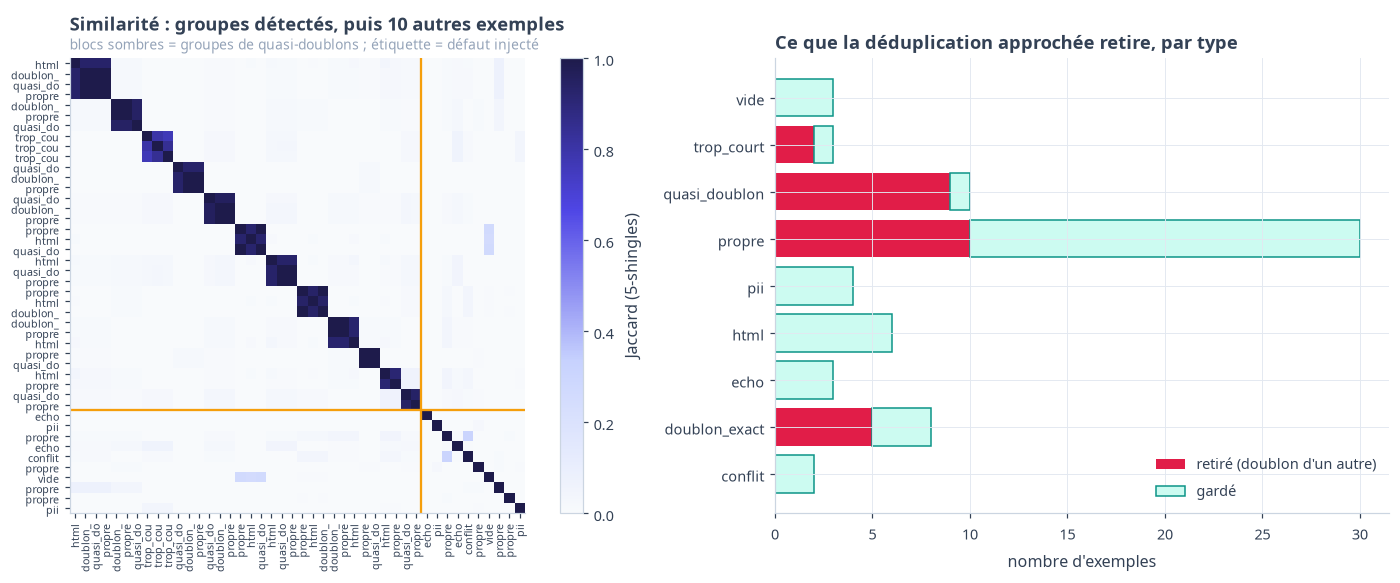

In [14]:
ordre = [i for g in sorted(groupes, key=len, reverse=True) for i in g]
autres = [i for i in range(len(brut)) if i not in ordre][:12]
sel = ordre[:34] + autres[:10]
Jm = np.array([[d8.jaccard(S[i], S[j]) for j in sel] for i in sel])
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
im = ax.imshow(Jm, cmap="aie_seq", vmin=0, vmax=1)
ax.set_xticks(range(len(sel)), [brut.kind[i][:8] for i in sel], rotation=90, fontsize=7)
ax.set_yticks(range(len(sel)), [brut.kind[i][:8] for i in sel], fontsize=7)
ax.axvline(len(ordre[:34]) - 0.5, color=AMBER, lw=1.5); ax.axhline(len(ordre[:34]) - 0.5, color=AMBER, lw=1.5)
ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.04, label="Jaccard (5-shingles)")
titre(ax, "Similarité : groupes détectés, puis 10 autres exemples",
      "blocs sombres = groupes de quasi-doublons ; étiquette = défaut injecté")
ax = axes[1]
dans_groupe = np.zeros(len(brut), bool)
for g in groupes:
    for i in a_retirer(g):
        dans_groupe[i] = True
tab = pd.crosstab(brut.kind, dans_groupe).reindex(columns=[False, True], fill_value=0)
ax.barh(tab.index, tab[True], color=ROSE, label="retiré (doublon d'un autre)")
ax.barh(tab.index, tab[False], left=tab[True], color=LIGHT[TEAL], edgecolor=TEAL, label="gardé")
ax.set_xlabel("nombre d'exemples")
ax.set_title("Ce que la déduplication approchée retire, par type")
ax.legend(loc="lower right")
finish(fig)
plt.show()

Les doublons exacts et la plupart des quasi-doublons sont regroupés avec leur original.
Des exemples « propres » figurent parmi les retirés : c'est leur jumeau (copie exacte,
variante de casse, version HTML de même texte) qui a été gardé à leur place, ce qui
revient au même pour le contenu.
On voit aussi passer d'autres types : une version HTML (identique une fois les balises
retirées) ou une réponse « écho »... Ce n'est pas un défaut de l'algorithme : ce sont
bien des quasi-doublons du point de vue du texte. Ce que l'on fait de chaque groupe
(garder le premier, le mieux noté, le plus récent) est une **décision de curation**.

### Pourquoi c'est indispensable à grande échelle

Comparons le temps de la comparaison exhaustive (toutes les paires, Jaccard exact) et de
MinHash + LSH sur des corpus synthétiques de taille croissante.

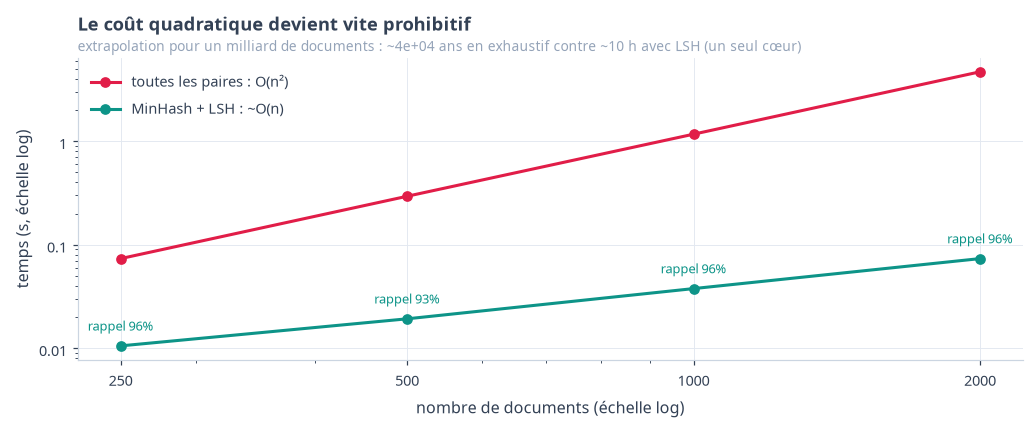

In [15]:
tailles = [250, 500, 1000, 2000]
t_pair, t_lsh, rappel = [], [], []
for n in tailles:
    dd, vp = d8.make_near_duplicate_corpus(n, dup_frac=0.2, edit_rate=0.1, seed=0)
    Sx = [d8.shingles(x, 3, "word") for x in dd]
    t0 = time.perf_counter()
    exh = {(i, j) for i in range(n) for j in range(i + 1, n) if d8.jaccard(Sx[i], Sx[j]) >= 0.4}
    t_pair.append(time.perf_counter() - t0)
    t0 = time.perf_counter()
    sx = d8.MinHasher(128).signatures(Sx)
    cx = d8.lsh_candidates(sx, *d8.lsh_optimal_params(128, 0.4))
    lsh = {p for p in cx if d8.jaccard(Sx[p[0]], Sx[p[1]]) >= 0.4}
    t_lsh.append(time.perf_counter() - t0)
    rappel.append(len(lsh & exh) / max(len(exh), 1))

fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(tailles, t_pair, "o-", color=ROSE, label="toutes les paires : O(n²)")
ax.plot(tailles, t_lsh, "o-", color=TEAL, label="MinHash + LSH : ~O(n)")
for n, tp, tl, rp in zip(tailles, t_pair, t_lsh, rappel):
    ax.annotate(f"rappel {rp:.0%}", (n, tl), xytext=(0, 10), textcoords="offset points", ha="center",
                fontsize=8.5, color=TEAL)
ax.set_xscale("log"); ax.set_yscale("log")
log_lisible(ax, "xy")
ax.set_xticks(tailles, [str(n) for n in tailles])
ax.set_xlabel("nombre de documents (échelle log)")
ax.set_ylabel("temps (s, échelle log)")
n_web = 1e9
titre(ax, "Le coût quadratique devient vite prohibitif",
      f"extrapolation pour un milliard de documents : ~{t_pair[-1] * (n_web / tailles[-1]) ** 2 / 3.15e7:.0e} ans "
      f"en exhaustif contre ~{t_lsh[-1] * n_web / tailles[-1] / 3600:.0f} h avec LSH (un seul cœur)")
ax.legend(loc="upper left")
finish(fig)
plt.show()

La pente 2 (en log-log) de la comparaison exhaustive contre la pente 1 du LSH résume
tout : à l'échelle d'un corpus de pré-entraînement, seule la seconde est envisageable,
pour un rappel très proche de 100 %. Le livre cite des bibliothèques qui le font
(datasketch, dedupe, deduplicate-text-datasets...) ; les filtres de Bloom servent, eux, à
tester très vite l'appartenance à un ensemble déjà vu.

> **À retenir.** MinHash résume un ensemble de shingles par $k$ minimums de hachages et
> estime Jaccard sans biais (erreur $\sqrt{J(1-J)/k}$). LSH découpe la signature en $b$
> bandes de $r$ lignes : une paire de similarité $s$ devient candidate avec probabilité
> $1-(1-s^r)^b$, une courbe en S réglable. On passe de $O(n^2)$ à environ $O(n)$.